11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 4ms/step - accuracy: 0.8773 - loss: 0.4186 - val_accuracy: 0.9547 - val_loss: 0.1425
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9684 - loss: 0.1041 - val_accuracy: 0.9721 - val_loss: 0.0874
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9776 - loss: 0.0711 - val_accuracy: 0.9754 - val_loss: 0.0765
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.9853 - loss: 0.0490 - val_accuracy: 0.9765 - val_loss: 0.0738
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - accuracy: 0.9877 - loss: 0.0384 - val_accuracy: 0.9754 - val_loss: 0.0800
313/313 - 1s - 2ms/step - accuracy: 0.9754 - loss: 0.0800
Test Accuracy: 0.98
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
Predicted labels: [7 2 1 0 4]
True labels: [7 2 1 0 4]


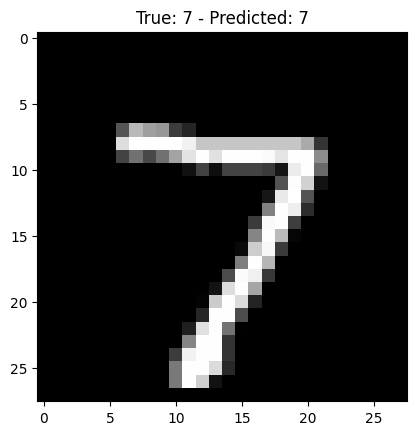

In [1]:
# Step 1: Import libraries
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.datasets import mnist
import matplotlib.pyplot as plt

# Step 2: Load dataset (MNIST handwritten digits)
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# Normalize (scale) data between 0 and 1
x_train, x_test = x_train / 255.0, x_test / 255.0

# Step 3: Build Deep Learning Model
model = Sequential([
    Flatten(input_shape=(28,28)),         # Input Layer (28x28 image → 784 features)
    Dense(128, activation='relu'),        # Hidden Layer 1
    Dense(64, activation='relu'),         # Hidden Layer 2
    Dense(10, activation='softmax')       # Output Layer (10 classes: digits 0–9)
])

# Step 4: Compile Model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Step 5: Train Model
history = model.fit(x_train, y_train, epochs=5, validation_data=(x_test, y_test))

# Step 6: Evaluate Model
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print(f"Test Accuracy: {test_acc:.2f}")

# Step 7: Make Predictions
predictions = model.predict(x_test[:5])
print("Predicted labels:", predictions.argmax(axis=1))
print("True labels:", y_test[:5])

# Step 8: Plot first test image
plt.imshow(x_test[0], cmap='gray')
plt.title(f"True: {y_test[0]} - Predicted: {predictions.argmax(axis=1)[0]}")
plt.show()


In [5]:
import cv2

# Load Haar Cascade classifier for face detection
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

# Open webcam
cap = cv2.VideoCapture(0)

while True:
    ret, frame = cap.read()

    # Check if frame is successfully read
    if not ret:
        print("Error: Could not read frame.")
        break

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # Detect faces
    faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5)

    # Draw rectangle around faces
    for (x, y, w, h) in faces:
        cv2.rectangle(frame, (x, y), (x+w, y+h), (255, 0, 0), 2)

    cv2.imshow('Face Detection', frame)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()

Error: Could not read frame.


In [4]:
# Step 9: Plot training and validation accuracy and loss

# Get the history from the model training
history_dict = history.history

# Plot training and validation accuracy
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_dict['accuracy'], label='Training Accuracy')
plt.plot(history_dict['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

# Plot training and validation loss
plt.subplot(1, 2, 2)
plt.plot(history_dict['loss'], label='Training Loss')
plt.plot(history_dict['val_loss'], label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

NameError: name 'history' is not defined

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.1/100.1 MB 7.8 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for face-recognition-models: filename=face_recognition_models-0.3.0-py2.py3-none-any.whl size=100566166 sha256=d58ead7c6fbc3950b0e5d327d6366327a0c4e1aaac10c767f88db110379b8941
  Stored in directory: /root/.cache/pip/wheels/8f/47/c8/f44c5aebb7507f7c8a2c0bd23151d732d0f0bd6884ad4ac635
Successfully built face-recognition-models


In [1]:
import cv2
import mediapipe as mp
import pyautogui
from collections import deque

# ------------------ Mediapipe Setup ------------------
mp_hands = mp.solutions.hands
mp_drawing = mp.solutions.drawing_utils
hands = mp_hands.Hands(max_num_hands=1, min_detection_confidence=0.7)

cap = cv2.VideoCapture(0)

# ------------------ Gesture Stability ------------------
gesture_history = deque(maxlen=10)  # store last 10 gestures
prev_x, prev_y = 0, 0  # for smooth mouse movement

# ------------------ Finger Counting ------------------
def count_fingers(hand_landmarks, handedness):
    finger_tips = [8, 12, 16, 20]  # Index, Middle, Ring, Pinky tips
    finger_pips = [6, 10, 14, 18]  # PIP joints
    count = 0
    threshold = 0.02  # tolerance

    # Other 4 fingers
    for tip, pip in zip(finger_tips, finger_pips):
        if hand_landmarks.landmark[tip].y < hand_landmarks.landmark[pip].y - threshold:
            count += 1

    # Thumb check (depends on left/right hand)
    if handedness == "Right":
        if hand_landmarks.landmark[4].x < hand_landmarks.landmark[3].x - threshold:
            count += 1
    else:  # Left hand
        if hand_landmarks.landmark[4].x > hand_landmarks.landmark[3].x + threshold:
            count += 1

    return count

# ------------------ Main Loop ------------------
while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        break

    frame = cv2.flip(frame, 1)
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    results = hands.process(rgb)

    if results.multi_hand_landmarks:
        for idx, hand_landmarks in enumerate(results.multi_hand_landmarks):
            mp_drawing.draw_landmarks(frame, hand_landmarks, mp_hands.HAND_CONNECTIONS)

            # Detect left/right hand
            handedness = results.multi_handedness[idx].classification[0].label

            fingers = count_fingers(hand_landmarks, handedness)
            gesture_history.append(fingers)

            # Stable gesture (debouncing)
            if gesture_history.count(fingers) > 7:
                current_gesture = fingers

                # ------------------ Gesture Mappings ------------------
                if current_gesture == 0:  # ✊ Fist
                    cv2.putText(frame, "Stop / Pause", (50, 100),
                                cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
                    # pyautogui.press("space")

                elif current_gesture == 1:  # ☝ One finger
                    cv2.putText(frame, "Next Slide", (50, 100),
                                cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 0), 2)
                    # pyautogui.press("right")

                    # Mouse control with index finger
                    index_tip = hand_landmarks.landmark[8]
                    h, w, _ = frame.shape
                    x, y = int(index_tip.x * w), int(index_tip.y * h)

                    # Smooth movement
                    smooth_factor = 0.2
                    prev_x = prev_x + (x - prev_x) * smooth_factor
                    prev_y = prev_y + (y - prev_y) * smooth_factor
                    pyautogui.moveTo(int(prev_x * 3), int(prev_y * 3))  # scale to screen size
                    cv2.circle(frame, (x, y), 10, (0, 255, 255), -1)

                elif current_gesture == 2:  # ✌ Two fingers
                    cv2.putText(frame, "Previous Slide", (50, 100),
                                cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 0), 2)
                    # pyautogui.press("left")

                elif current_gesture == 3:  # Three fingers
                    cv2.putText(frame, "Volume Up", (50, 100),
                                cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 255), 2)
                    # pyautogui.press("volumeup")

                elif current_gesture == 4:  # Four fingers
                    cv2.putText(frame, "Volume Down", (50, 100),
                                cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 255), 2)
                    # pyautogui.press("volumedown")

                elif current_gesture == 5:  # 🖐 Palm
                    cv2.putText(frame, "Play / Resume", (50, 100),
                                cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 0, 0), 2)
                    # pyautogui.press("playpause")

    # ------------------ Display ------------------
    cv2.imshow("Hand Gesture Control", frame)
    if cv2.waitKey(1) & 0xFF == ord("q"):
        break

cap.release()
cv2.destroyAllWindows()


ModuleNotFoundError: No module named 'mediapipe'